<a href="https://colab.research.google.com/github/MuhammadUmarAshrafDE/Data-Visualization/blob/main/EcoMove_Colab_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1 – Install the dashboard library
Colab already has pandas, NumPy, Matplotlib, seaborn, Plotly and openpyxl. Only Dash needs installing.

In [16]:
!pip install -q dash

## Step 2 – Upload the dataset

In [17]:
import os
if not os.path.exists("EcoMoveMobility.xlsx"):
    from google.colab import files
    uploaded = files.upload()          # choose the EcoMove Excel file
    os.rename(next(iter(uploaded)), "EcoMoveMobility.xlsx")
print("Dataset ready:", os.path.exists("EcoMoveMobility.xlsx"))

Saving [5442] EcoMoveMobility DV.xlsx to [5442] EcoMoveMobility DV (1).xlsx
Dataset ready: True


## Step 3 – Data understanding, preparation and Figures 1–7 (Appendix A)

In [1]:
"""
COM7021 Data Visualisation - EcoMove Mobility Investigation
Part 1: data understanding, preparation and static visualisations (Figures 1-7).

Run:  python ecomove_analysis.py
Needs: pandas, numpy, matplotlib, seaborn, openpyxl
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

DATA_FILE = "EcoMoveMobility.xlsx"
OUT = Path("figures")
OUT.mkdir(exist_ok=True)

# ---------- Consistent visual style ----------
BLUE = "#1f5f8b"      # main colour for normal data
ORANGE = "#e07b39"    # highlight colour, used only to draw attention
GREY = "#b8c2cc"      # de-emphasised data
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", facecolor="white")
    plt.close(fig)

In [5]:
# =====================================================================
# 1. LOAD AND UNDERSTAND THE DATA
# =====================================================================
df = pd.read_excel("/content/[5442] EcoMoveMobility DV.xlsx")

print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:",
      df.duplicated(subset=df.columns[1:]).sum())

Shape: (5000, 18)

Data types:
 Record_ID                    object
Date                          int64
City                         object
Country                      object
Transport_Mode               object
Route_Type                   object
Weather                      object
Event_Day                    object
Passengers                    int64
Trips                         int64
Average_Delay_Minutes       float64
On_Time_Percentage          float64
Ticket_Revenue_EUR          float64
Operating_Cost_EUR          float64
CO2_Saved_KG                float64
Energy_Consumption_KWh      float64
Customer_Rating             float64
Accessibility_Complaints      int64
dtype: object

Missing values per column:
 Record_ID                   0
Date                        0
City                        0
Country                     0
Transport_Mode              0
Route_Type                  0
Weather                     0
Event_Day                   0
Passengers                  0
Trips  

In [6]:
# =====================================================================
# 2. PREPARE THE DATA
# =====================================================================
# The Date column is stored as an Excel serial number (e.g. 45747),
# so it is converted into a real date.

df["Date"] = pd.to_datetime("1899-12-30") + pd.to_timedelta(df["Date"], unit="D")
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Year"] = df["Date"].dt.year

# Text columns become categories (smaller and faster to group)
cat_cols = ["City", "Country", "Transport_Mode", "Route_Type", "Weather", "Event_Day"]
for c in cat_cols:
    df[c] = df[c].astype("category")

# Check every city belongs to only one country (consistency check)
city_country = df.groupby("City", observed=True)["Country"].nunique()
print("\nCities linked to more than one country:", (city_country > 1).sum())

# Check value ranges for impossible values
print("\nOn-time % outside 0-100:", ((df.On_Time_Percentage < 0) | (df.On_Time_Percentage > 100)).sum())
print("Ratings outside 1-5:", ((df.Customer_Rating < 1) | (df.Customer_Rating > 5)).sum())
print("Negative numeric values:", (df.select_dtypes("number") < 0).sum().sum())

# Zero energy use only appears for Bike Share (human powered) - a real value, kept.
print("\nRows with zero energy use by mode:\n",
      df[df.Energy_Consumption_KWh == 0]["Transport_Mode"].value_counts())

# Outlier check with the IQR rule. Large values belong to Metro (very high
# capacity), so they are real and are kept rather than removed.
num_cols = df.select_dtypes("number").columns.drop("Year")
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"IQR outliers in {c}: {n_out}")

# New fields that make fair comparisons possible
df["Profit_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
df["Cost_Recovery"] = df["Ticket_Revenue_EUR"] / df["Operating_Cost_EUR"]

print("\nSummary statistics:\n", df[num_cols].describe().T.round(2))
df.to_csv("ecomove_clean.csv", index=False)

# Mode-level summary used by several charts
mode = df.groupby("Transport_Mode", observed=True).agg(
    Passengers=("Passengers", "sum"),
    Revenue=("Ticket_Revenue_EUR", "sum"),
    Cost=("Operating_Cost_EUR", "sum"),
    CO2=("CO2_Saved_KG", "sum"),
    Complaints=("Accessibility_Complaints", "sum"),
    Delay=("Average_Delay_Minutes", "mean"),
    OnTime=("On_Time_Percentage", "mean"),
    Rating=("Customer_Rating", "mean"),
)
mode["Cost_Recovery_%"] = mode.Revenue / mode.Cost * 100
mode["CO2_per_Passenger_KG"] = mode.CO2 / mode.Passengers
mode["Complaints_per_10k"] = mode.Complaints / mode.Passengers * 10_000
mode["Share_of_Passengers_%"] = mode.Passengers / mode.Passengers.sum() * 100
print("\nTransport mode scorecard:\n", mode.round(2))


Cities linked to more than one country: 0

On-time % outside 0-100: 0
Ratings outside 1-5: 0
Negative numeric values: 0

Rows with zero energy use by mode:
 Transport_Mode
Bike Share       759
Bus                0
E-Scooter          0
Metro              0
Park and Ride      0
Tram               0
Name: count, dtype: int64
IQR outliers in Passengers: 525
IQR outliers in Trips: 955
IQR outliers in Average_Delay_Minutes: 11
IQR outliers in On_Time_Percentage: 10
IQR outliers in Ticket_Revenue_EUR: 591
IQR outliers in Operating_Cost_EUR: 780
IQR outliers in CO2_Saved_KG: 685
IQR outliers in Energy_Consumption_KWh: 465
IQR outliers in Customer_Rating: 10
IQR outliers in Accessibility_Complaints: 472

Summary statistics:
                            count      mean       std     min      25%  \
Passengers                5000.0   8181.94  10018.72   64.00  1411.75   
Trips                     5000.0    121.77    155.79   11.00    36.00   
Average_Delay_Minutes     5000.0      4.35      2.39  

In [7]:
# =====================================================================
# FIGURE 1 - TIME SERIES: Monthly demand and delay
# =====================================================================
monthly = df.groupby("Month").agg(
    Passengers=("Passengers", "sum"),
    Delay=("Average_Delay_Minutes", "mean"),
)
monthly["Rolling"] = monthly["Passengers"].rolling(3, center=True).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(monthly.index, monthly.Passengers / 1e6, color=GREY, marker="o", lw=1.5,
         label="Monthly passengers")
ax1.plot(monthly.index, monthly.Rolling / 1e6, color=BLUE, lw=3,
         label="3-month moving average")
ax1.set_ylabel("Passengers (millions)")
ax1.set_title("Figure 1. Monthly passenger demand and average delay, 2024-2025")
ax1.legend(frameon=False, loc="lower left")
low = monthly.Passengers.idxmin()
ax1.annotate(f"Lowest month\n{low:%b %Y}", xy=(low, monthly.Passengers[low] / 1e6),
             xytext=(low - pd.Timedelta(days=210), 1.55),
             arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)
ax2.bar(monthly.index, monthly.Delay, width=20, color=BLUE)
ax2.axhline(df.Average_Delay_Minutes.mean(), color=ORANGE, ls="--", lw=1.5,
            label=f"Overall average ({df.Average_Delay_Minutes.mean():.1f} min)")
ax2.set_ylim(0, 5.5)
ax2.set_ylabel("Avg delay (min)")
ax2.legend(frameon=False, loc="upper left", fontsize=9)
ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
save(fig, "fig1_time_series")

In [8]:
# =====================================================================
# FIGURE 2 - COMPARISON: Passenger demand by city
# =====================================================================
city = (df.groupby(["City", "Country"], observed=True)["Passengers"].sum()
          .reset_index().sort_values("Passengers"))
city["Label"] = city.City.astype(str) + " (" + city.Country.astype(str) + ")"
colours = [ORANGE if i >= len(city) - 2 else BLUE for i in range(len(city))]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(city.Label, city.Passengers / 1e6, color=colours)
for b in bars:
    ax.text(b.get_width() + 0.05, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.2f}m", va="center", fontsize=10)
ax.set_xlabel("Total passengers 2024-2025 (millions)")
ax.set_title("Figure 2. Total passenger demand by city")
ax.set_xlim(0, city.Passengers.max() / 1e6 * 1.15)
save(fig, "fig2_city_comparison")

In [9]:
# =====================================================================
# FIGURE 3 - RELATIONSHIP: Correlation heatmap
# =====================================================================
corr_cols = {
    "Passengers": "Passengers", "Trips": "Trips",
    "Average_Delay_Minutes": "Delay (min)", "On_Time_Percentage": "On-time %",
    "Ticket_Revenue_EUR": "Revenue", "Operating_Cost_EUR": "Cost",
    "CO2_Saved_KG": "CO2 saved", "Energy_Consumption_KWh": "Energy use",
    "Customer_Rating": "Rating", "Accessibility_Complaints": "Access. complaints",
}
corr = df[list(corr_cols)].rename(columns=corr_cols).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation (r)", "shrink": 0.8},
            annot_kws={"size": 9}, ax=ax)
ax.set_title("Figure 3. Correlation between performance measures")
plt.xticks(rotation=40, ha="right")
save(fig, "fig3_correlation_heatmap")

In [10]:
# =====================================================================
# FIGURE 4 - DISTRIBUTION: Delay by weather -Box plot
# =====================================================================
order = (df.groupby("Weather", observed=True)["Average_Delay_Minutes"].median()
           .sort_values().index.tolist())
pal = {w: (ORANGE if w == "Snow" else BLUE) for w in order}

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x="Weather", y="Average_Delay_Minutes", hue="Weather",
            order=order, palette=pal, legend=False, dodge=False, width=0.6, fliersize=2, ax=ax)
counts = df.Weather.value_counts()
for i, w in enumerate(order):
    ax.text(i, -0.9, f"n={counts[w]}", ha="center", fontsize=9, color="dimgray")
ax.set_ylim(-1.3, 13)
ax.set_xlabel("Weather condition")
ax.set_ylabel("Average delay per record (minutes)")
ax.set_title("Figure 4. Distribution of delays by weather condition")
save(fig, "fig4_delay_distribution_weather")

In [11]:
# =====================================================================
# FIGURE 5 - PERFORMANCE INDICATOR: Cost recovery by mode
# =====================================================================
m5 = mode.sort_values("Cost_Recovery_%")
cols5 = [ORANGE if v < 100 else BLUE for v in m5["Cost_Recovery_%"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(m5.index.astype(str), m5["Cost_Recovery_%"], color=cols5)
ax.axvline(100, color="black", ls="--", lw=1.2)
ax.text(101, -0.6, "Break-even (100%)", fontsize=9)
for b, rev, cost in zip(bars, m5.Revenue, m5.Cost):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.0f}%  (rev €{rev/1e6:.1f}m / cost €{cost/1e6:.1f}m)",
            va="center", fontsize=9.5)
ax.set_xlim(0, 175)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Cost recovery (ticket revenue ÷ operating cost)")
ax.set_title("Figure 5. Financial performance KPI: cost recovery by transport mode")
save(fig, "fig5_cost_recovery_kpi")

In [12]:
# =====================================================================
# FIGURE 6 - DOT PLOT: sustainability and accessibility per passenger
# =====================================================================
m6 = mode.sort_values("CO2_per_Passenger_KG")
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
a.hlines(m6.index.astype(str), 0, m6.CO2_per_Passenger_KG, color=GREY, lw=2)
a.plot(m6.CO2_per_Passenger_KG, m6.index.astype(str), "o", color=BLUE, ms=10)
for y, v in enumerate(m6.CO2_per_Passenger_KG):
    a.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=9.5)
a.set_xlim(0, 0.22)
a.set_xlabel("CO2 saved per passenger (kg)")
a.set_title("Environmental benefit", fontsize=12)

b.hlines(m6.index.astype(str), 0, m6.Complaints_per_10k, color=GREY, lw=2)
c6 = [ORANGE if v > 17 else BLUE for v in m6.Complaints_per_10k]
b.scatter(m6.Complaints_per_10k, m6.index.astype(str), color=c6, s=100, zorder=3)
for y, v in enumerate(m6.Complaints_per_10k):
    b.text(v + 0.4, y, f"{v:.1f}", va="center", fontsize=9.5)
b.set_xlim(0, 21)
b.set_xlabel("Accessibility complaints per 10,000 passengers")
b.set_title("Accessibility issues", fontsize=12)
fig.suptitle("Figure 6. Sustainability and accessibility per passenger, by transport mode",
             fontsize=14, fontweight="bold", y=1.02)
save(fig, "fig6_sustainability_accessibility")

In [13]:
# =====================================================================
# FIGURE 7 - DIVERGING BAR: effect of major event days
# =====================================================================
ev = df.groupby("Event_Day", observed=True).agg(
    Passengers=("Passengers", "mean"), Delay=("Average_Delay_Minutes", "mean"),
    OnTime=("On_Time_Percentage", "mean"), Rating=("Customer_Rating", "mean"))
change = (ev.loc["Yes"] / ev.loc["No"] - 1) * 100
change.index = ["Passengers per record", "Average delay", "On-time %", "Customer rating"]
change = change.sort_values()
# For delay, a rise is bad; colour by whether the change is good or bad for passengers
good = {"Passengers per record": True, "Average delay": False,
        "On-time %": True, "Customer rating": True}
cols7 = [BLUE if (v > 0) == good[k] else ORANGE for k, v in change.items()]

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(change.index, change.values, color=cols7)
ax.axvline(0, color="black", lw=1)
for bar_, v in zip(bars, change.values):
    ax.text(v + (1 if v > 0 else -1), bar_.get_y() + bar_.get_height() / 2,
            f"{v:+.1f}%", va="center", ha="left" if v > 0 else "right", fontsize=10)
ax.set_xlim(-15, 38)
ax.set_xlabel("% difference on event days compared with normal days")
ax.set_title("Figure 7. How major event days change demand and service quality")
ax.text(37, -0.45, "Blue = higher demand / better service   Orange = worse service", ha="right",
        fontsize=9, color="dimgray")
save(fig, "fig7_event_day_effect")

# Small tables used in the report
mode.round(3).to_csv("table_mode_scorecard.csv")
df.groupby("Weather", observed=True).agg(
    Records=("Record_ID", "count"), Avg_Passengers=("Passengers", "mean"),
    Avg_Delay=("Average_Delay_Minutes", "mean"), OnTime=("On_Time_Percentage", "mean"),
    Rating=("Customer_Rating", "mean")).round(2).to_csv("table_weather.csv")
print("\nAll figures saved to", OUT.resolve())


All figures saved to /content/figures


## Step 4 – Show the saved figures

figures/fig1_time_series.png


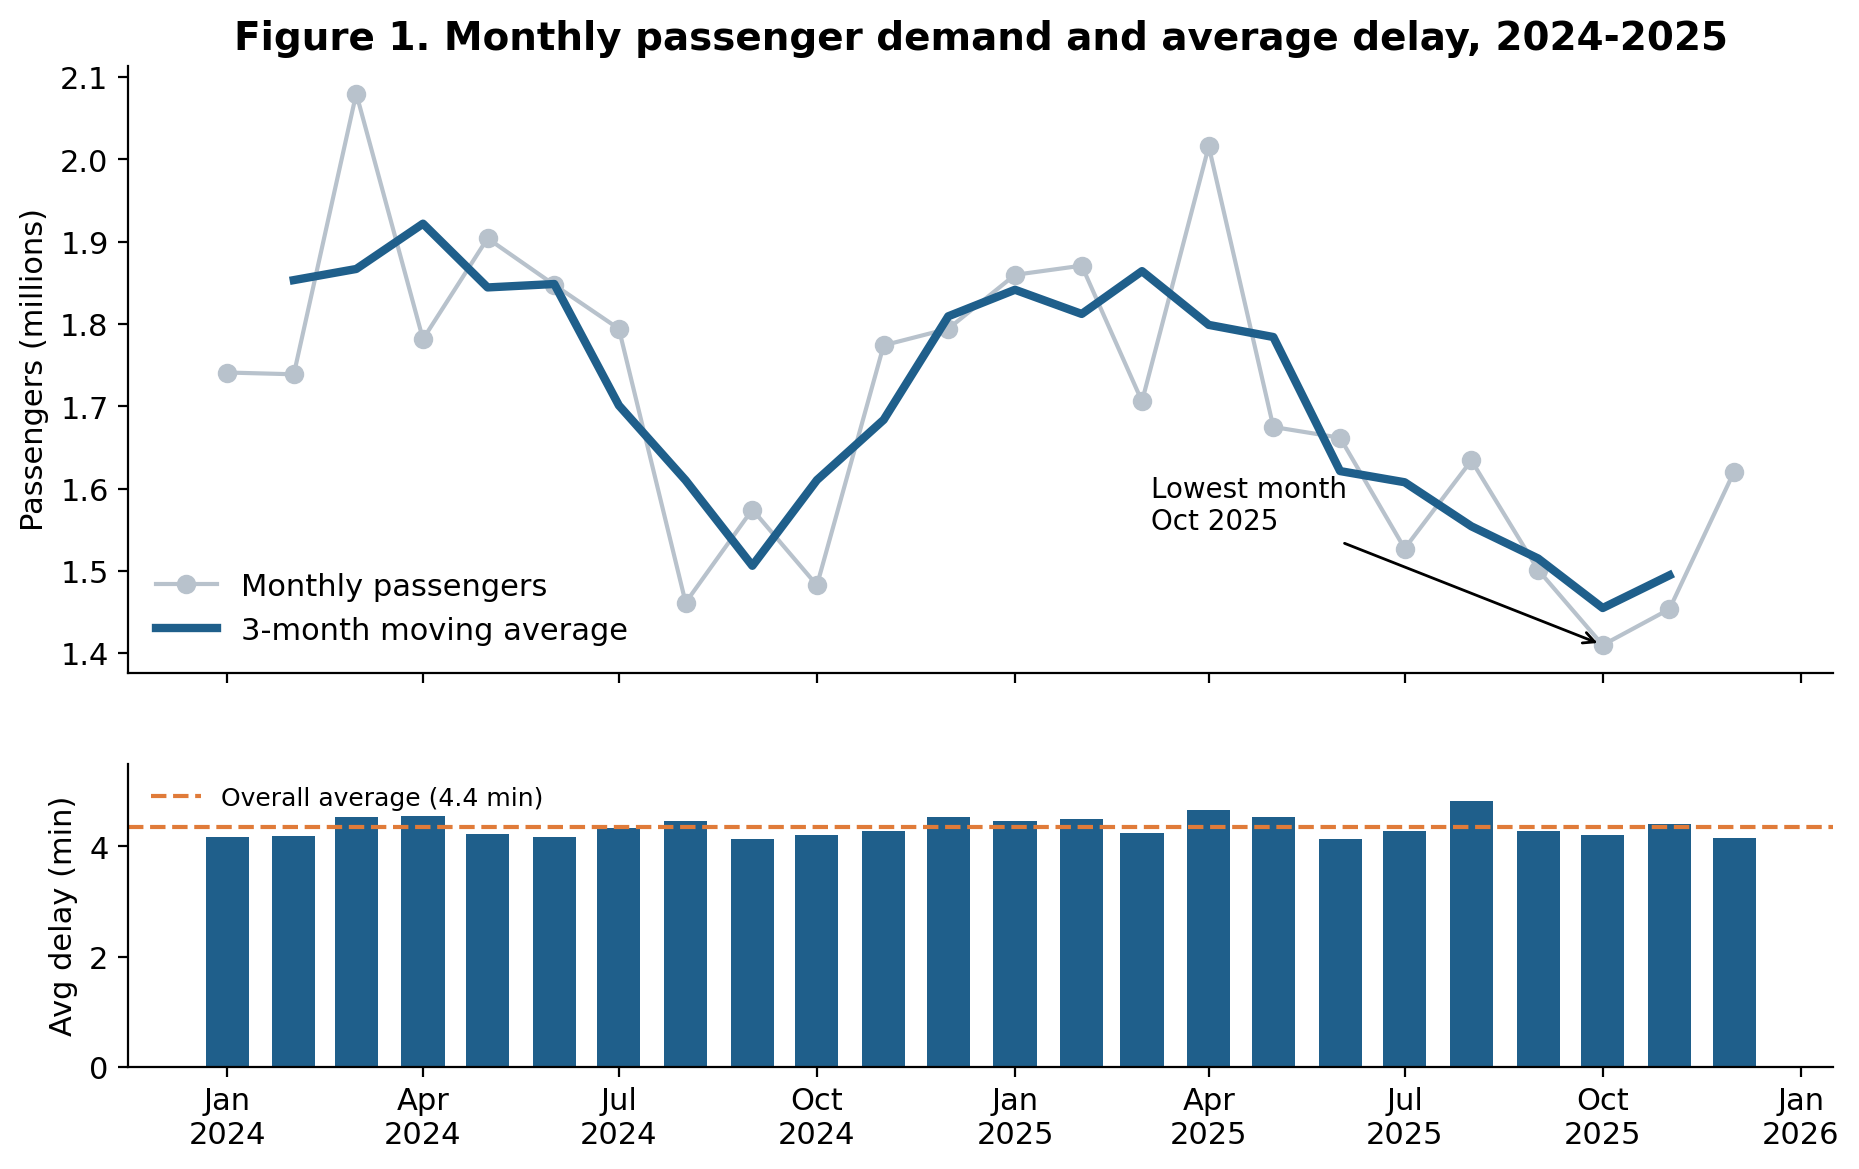

figures/fig2_city_comparison.png


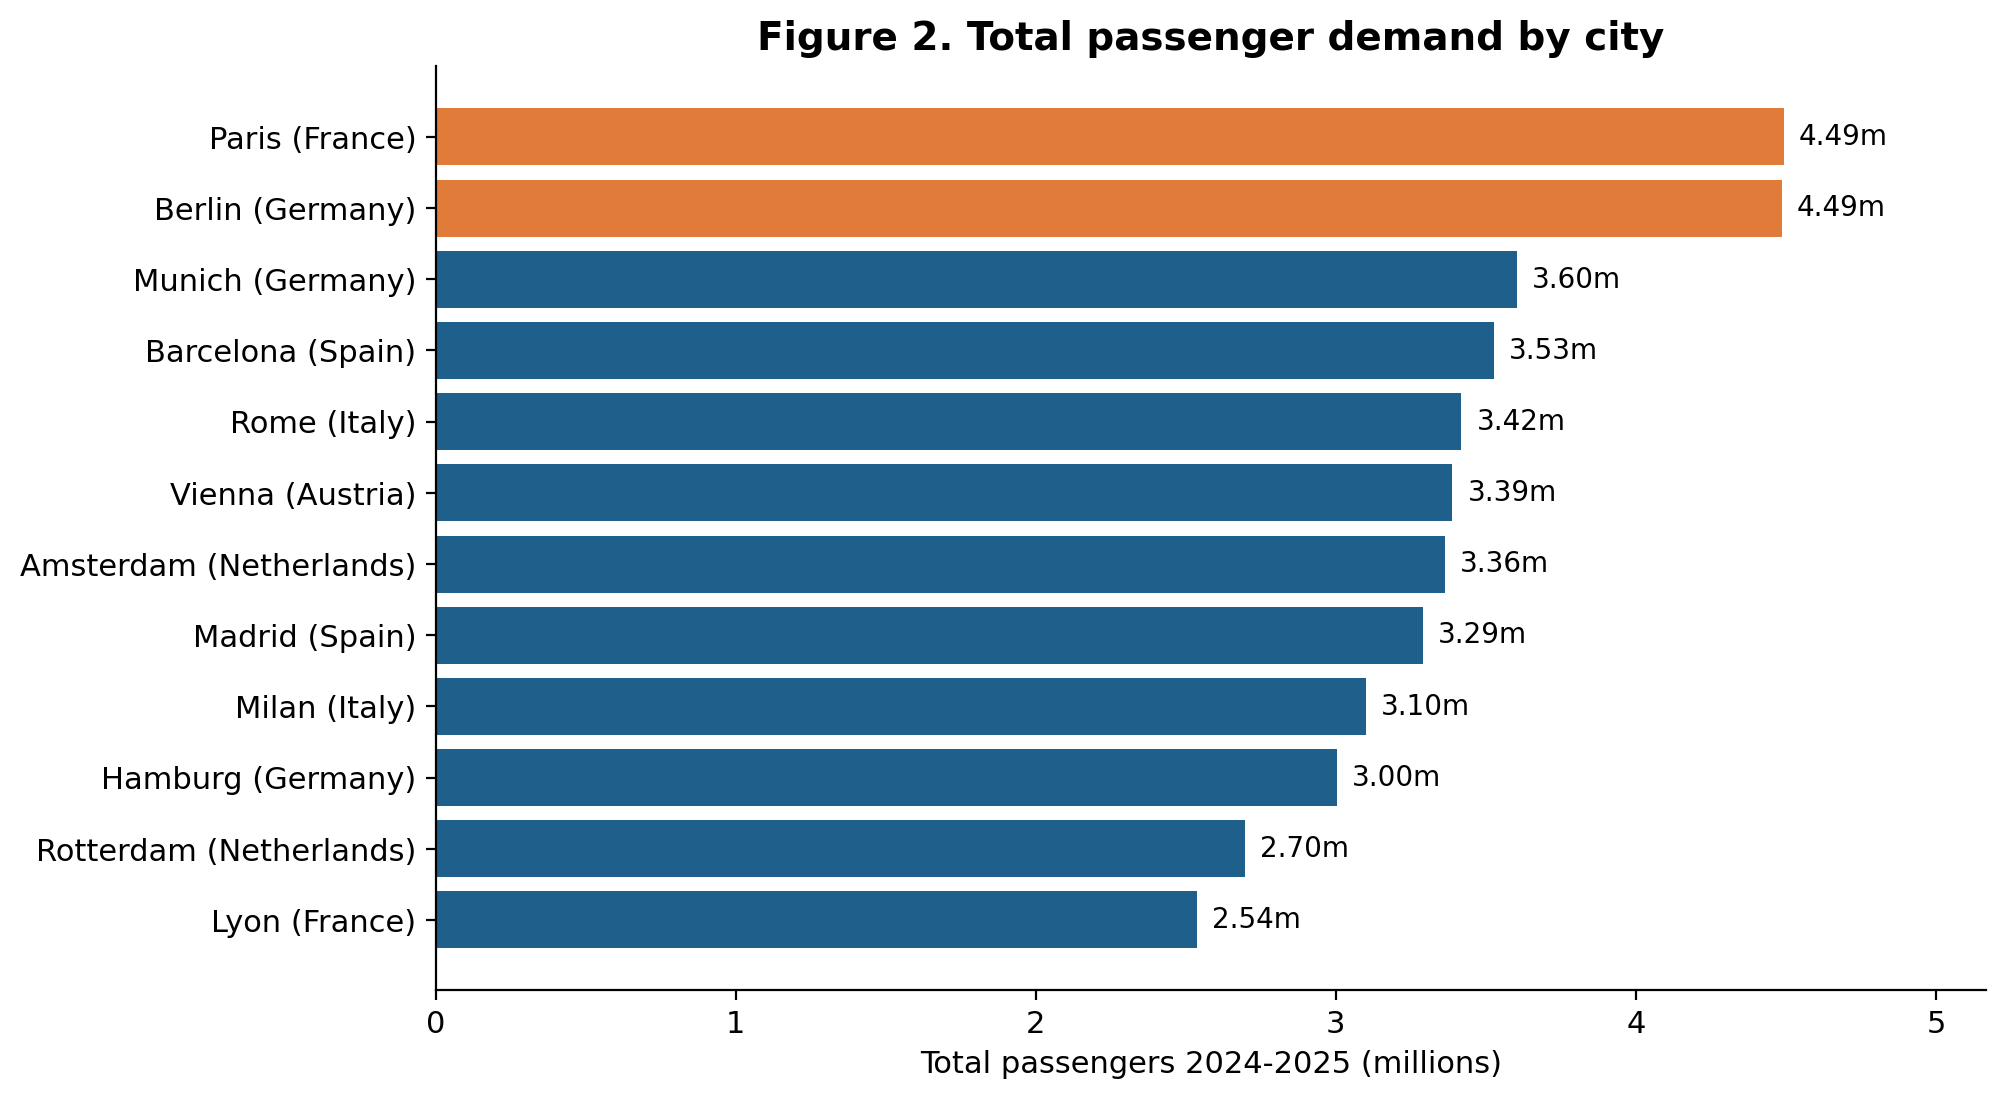

figures/fig3_correlation_heatmap.png


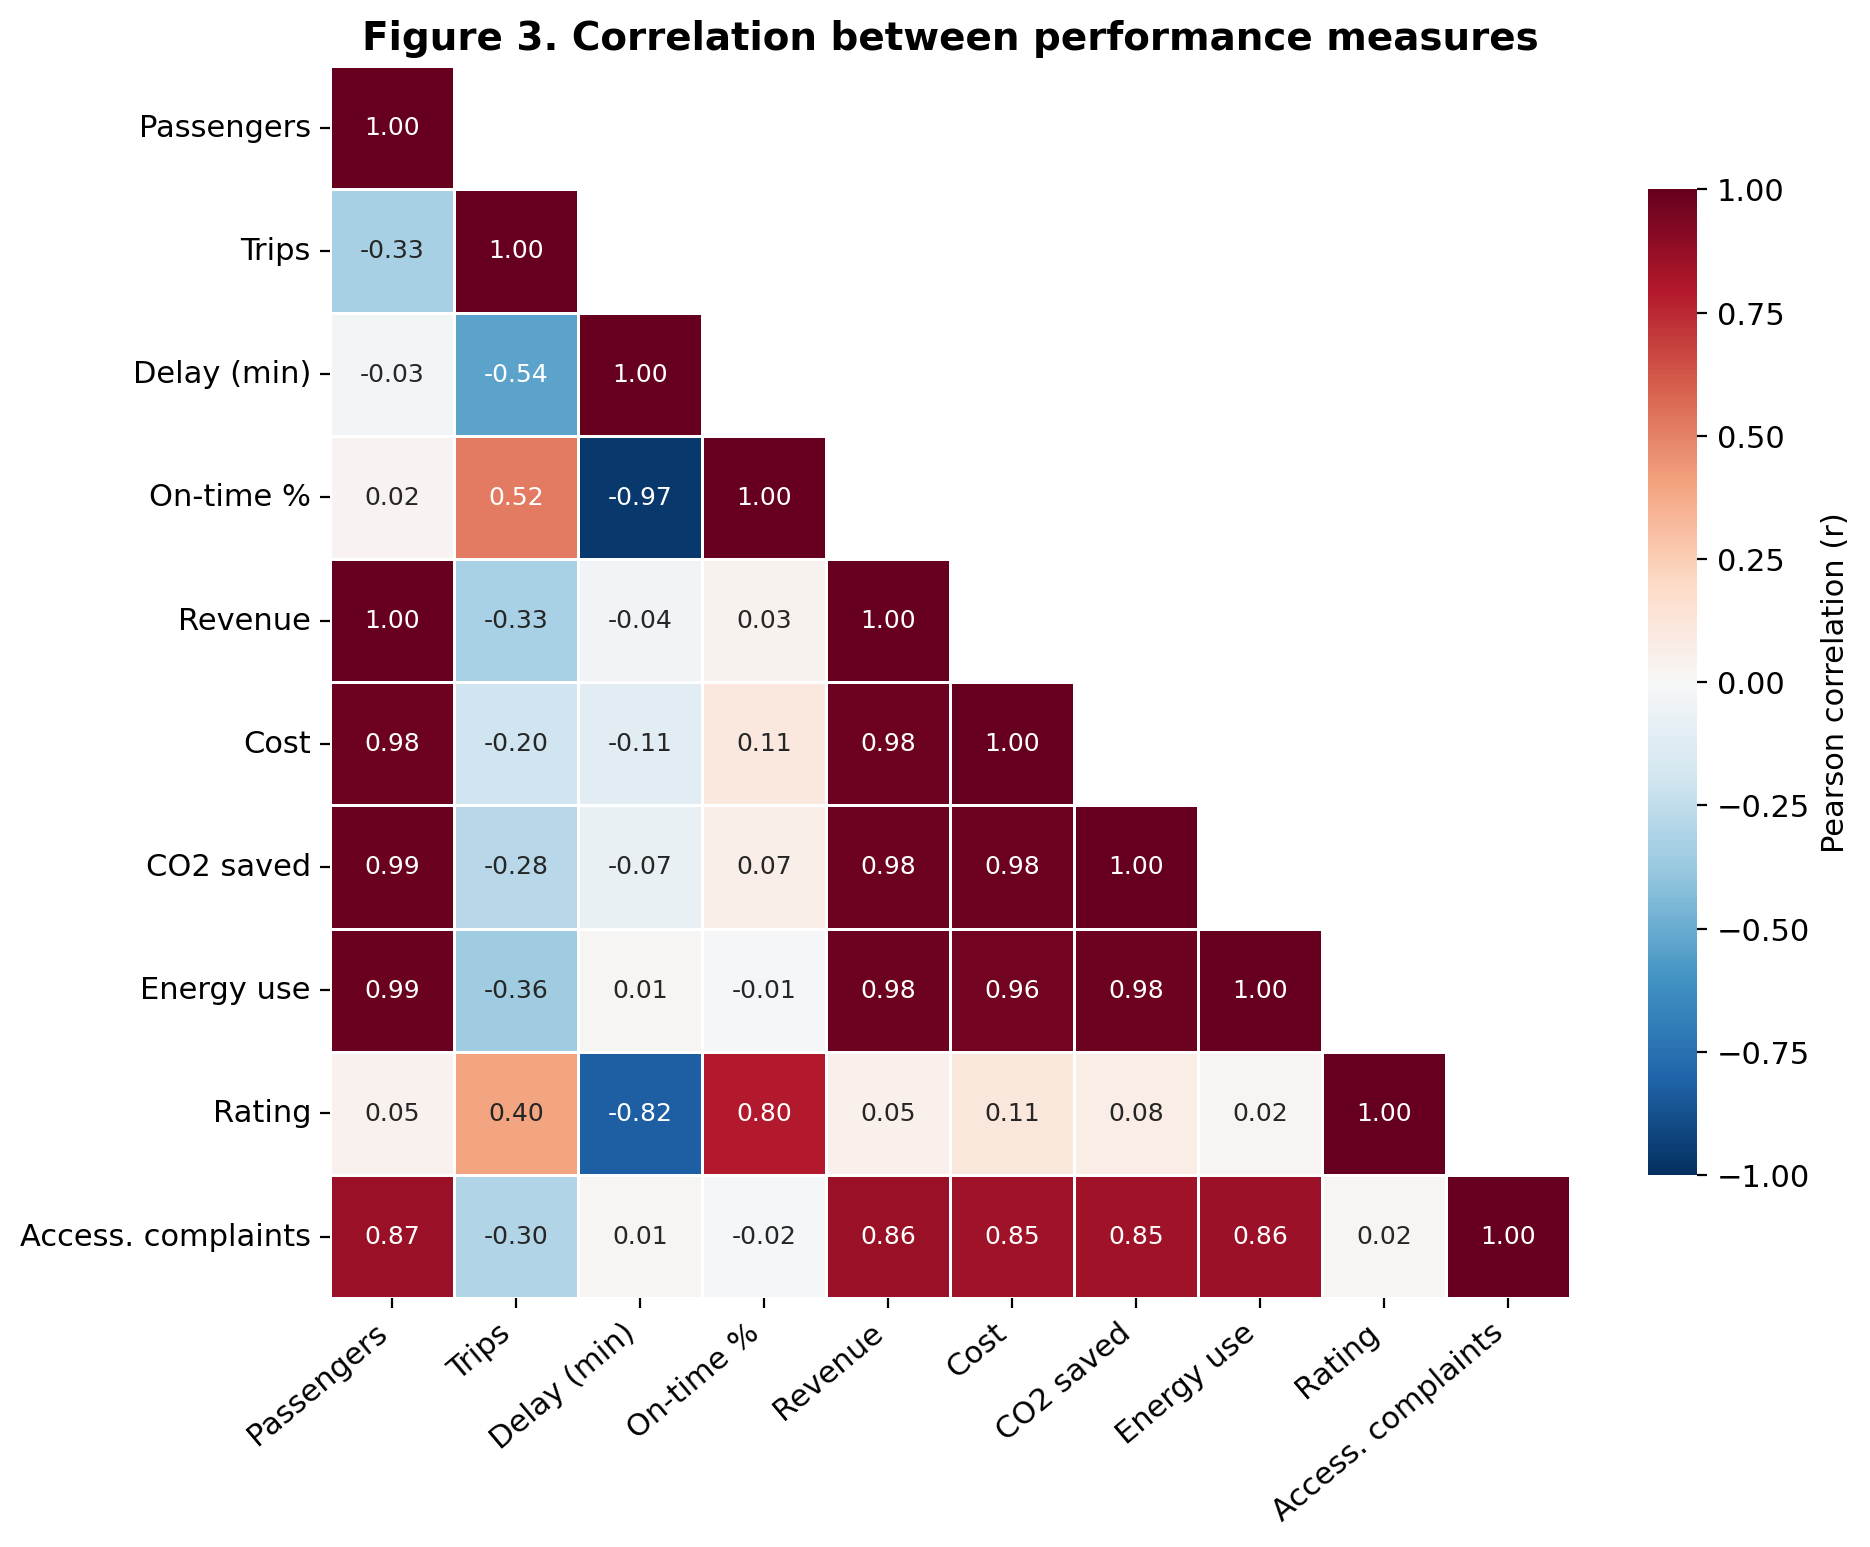

figures/fig4_delay_distribution_weather.png


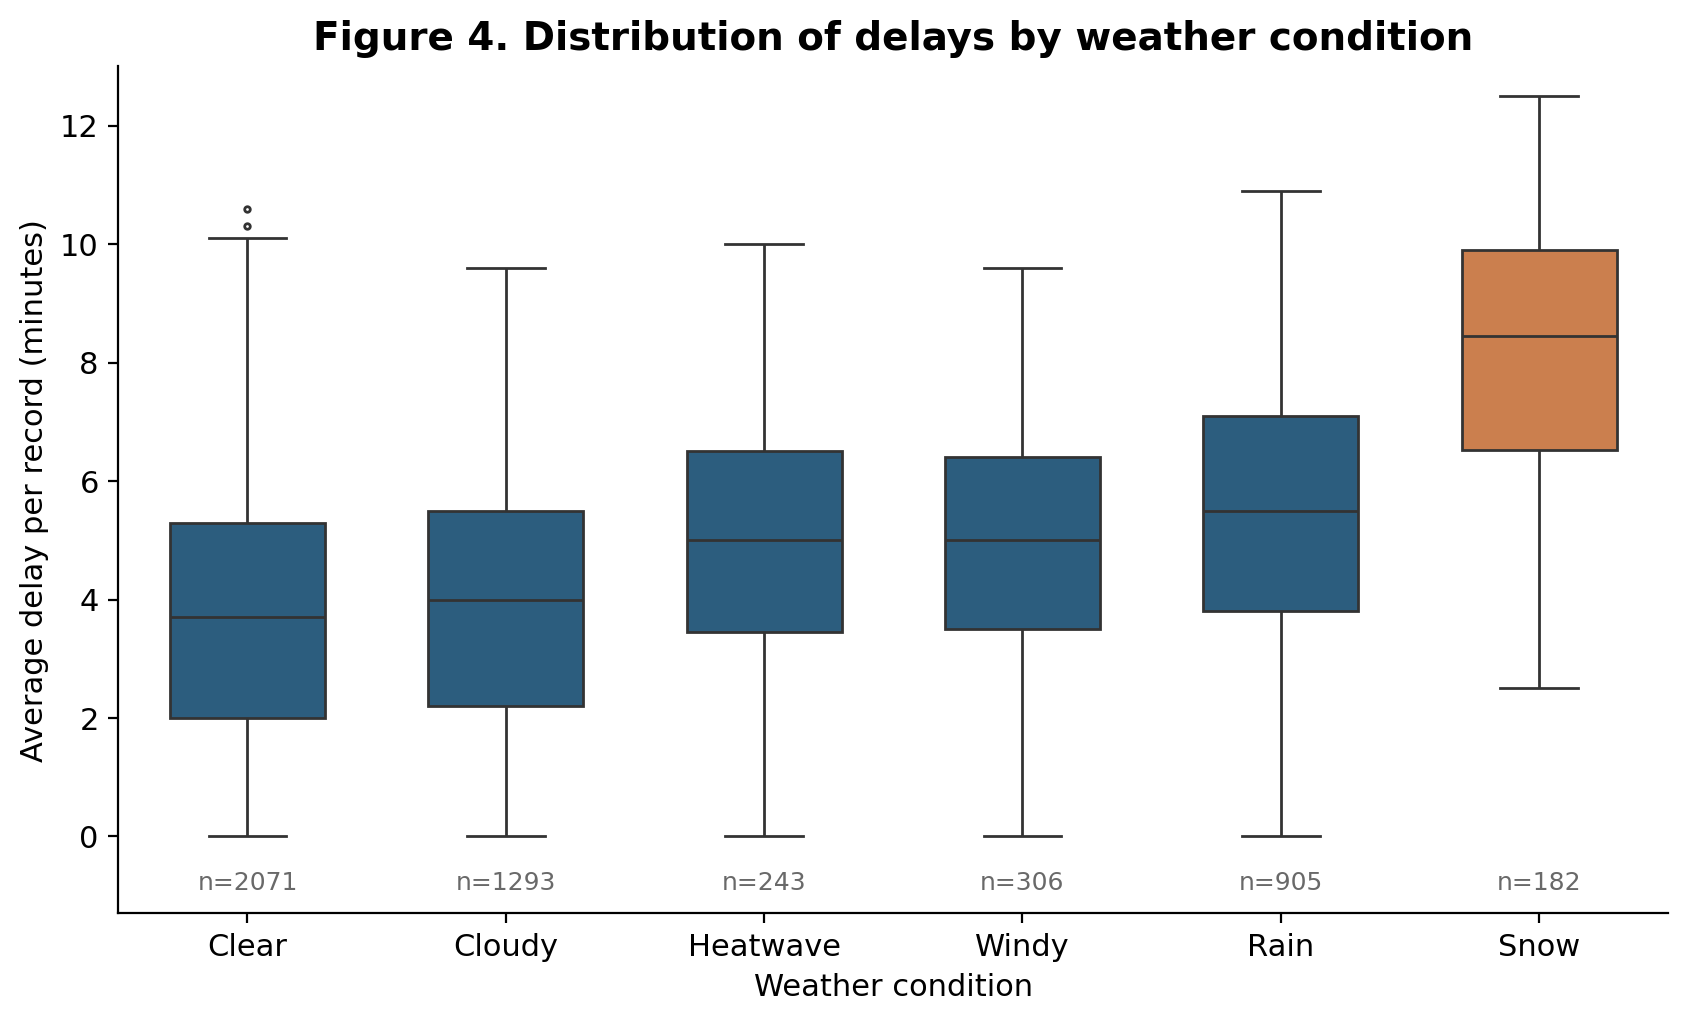

figures/fig5_cost_recovery_kpi.png


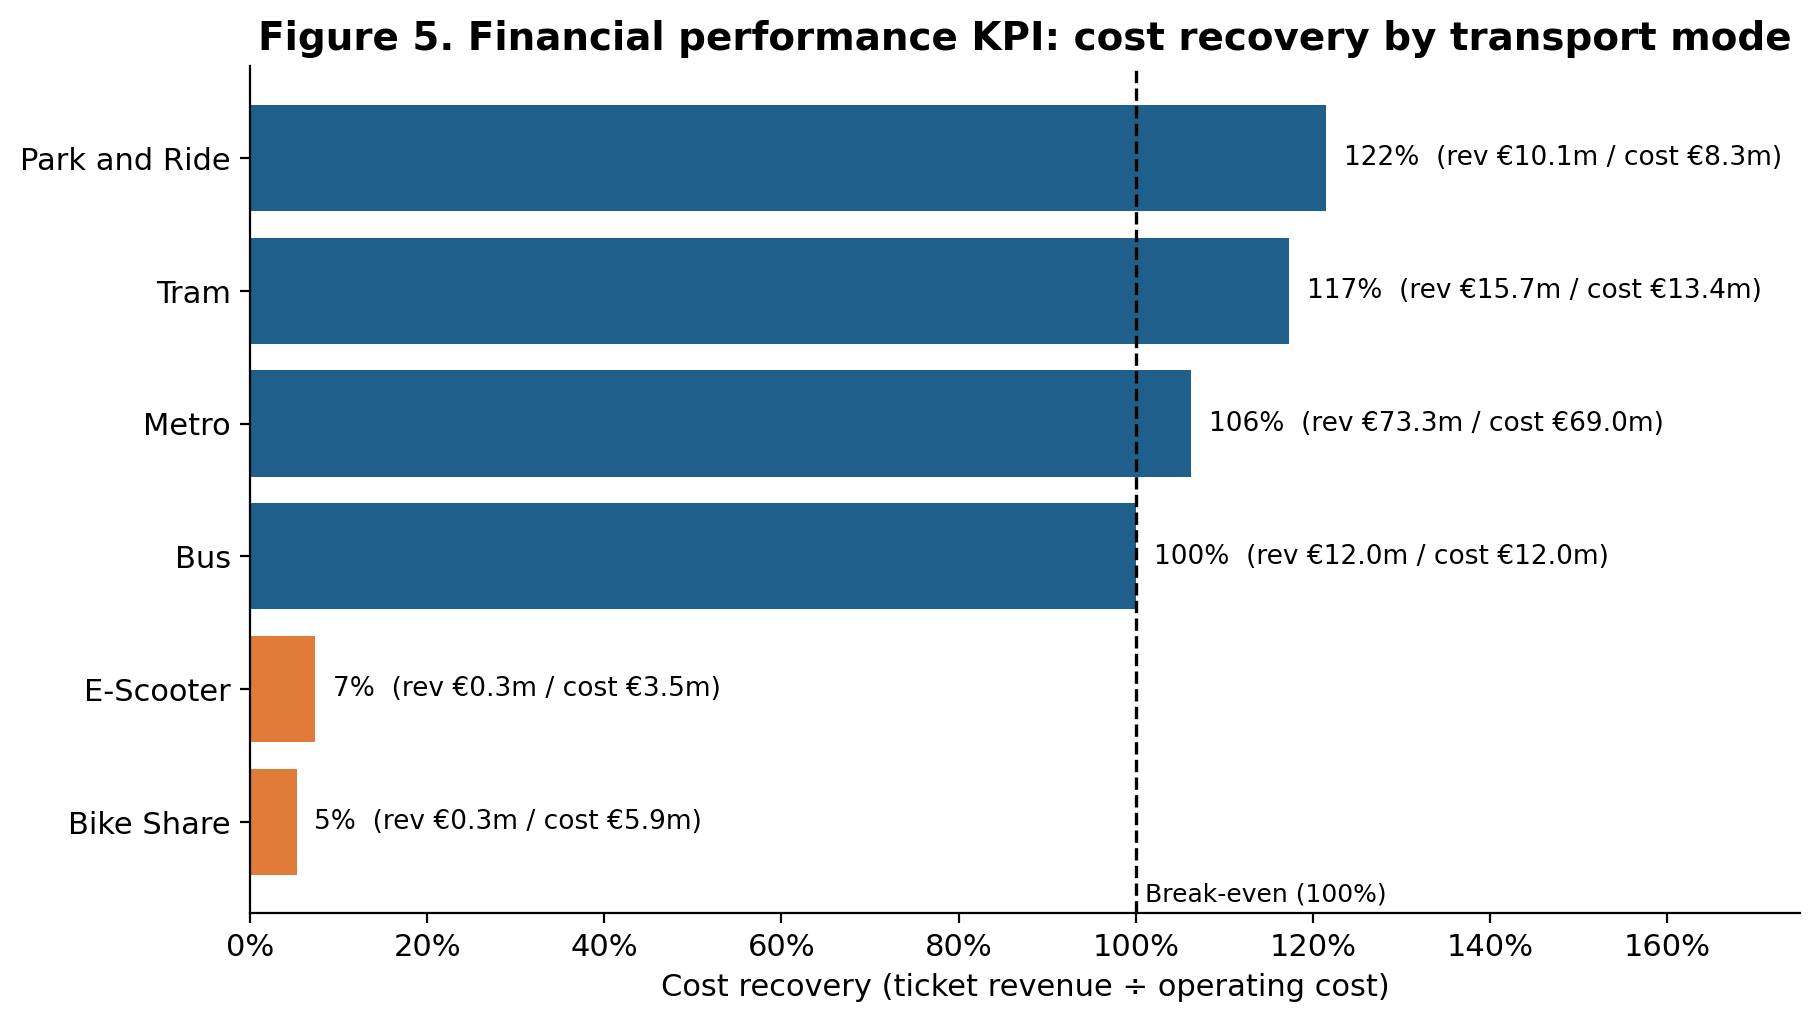

figures/fig6_sustainability_accessibility.png


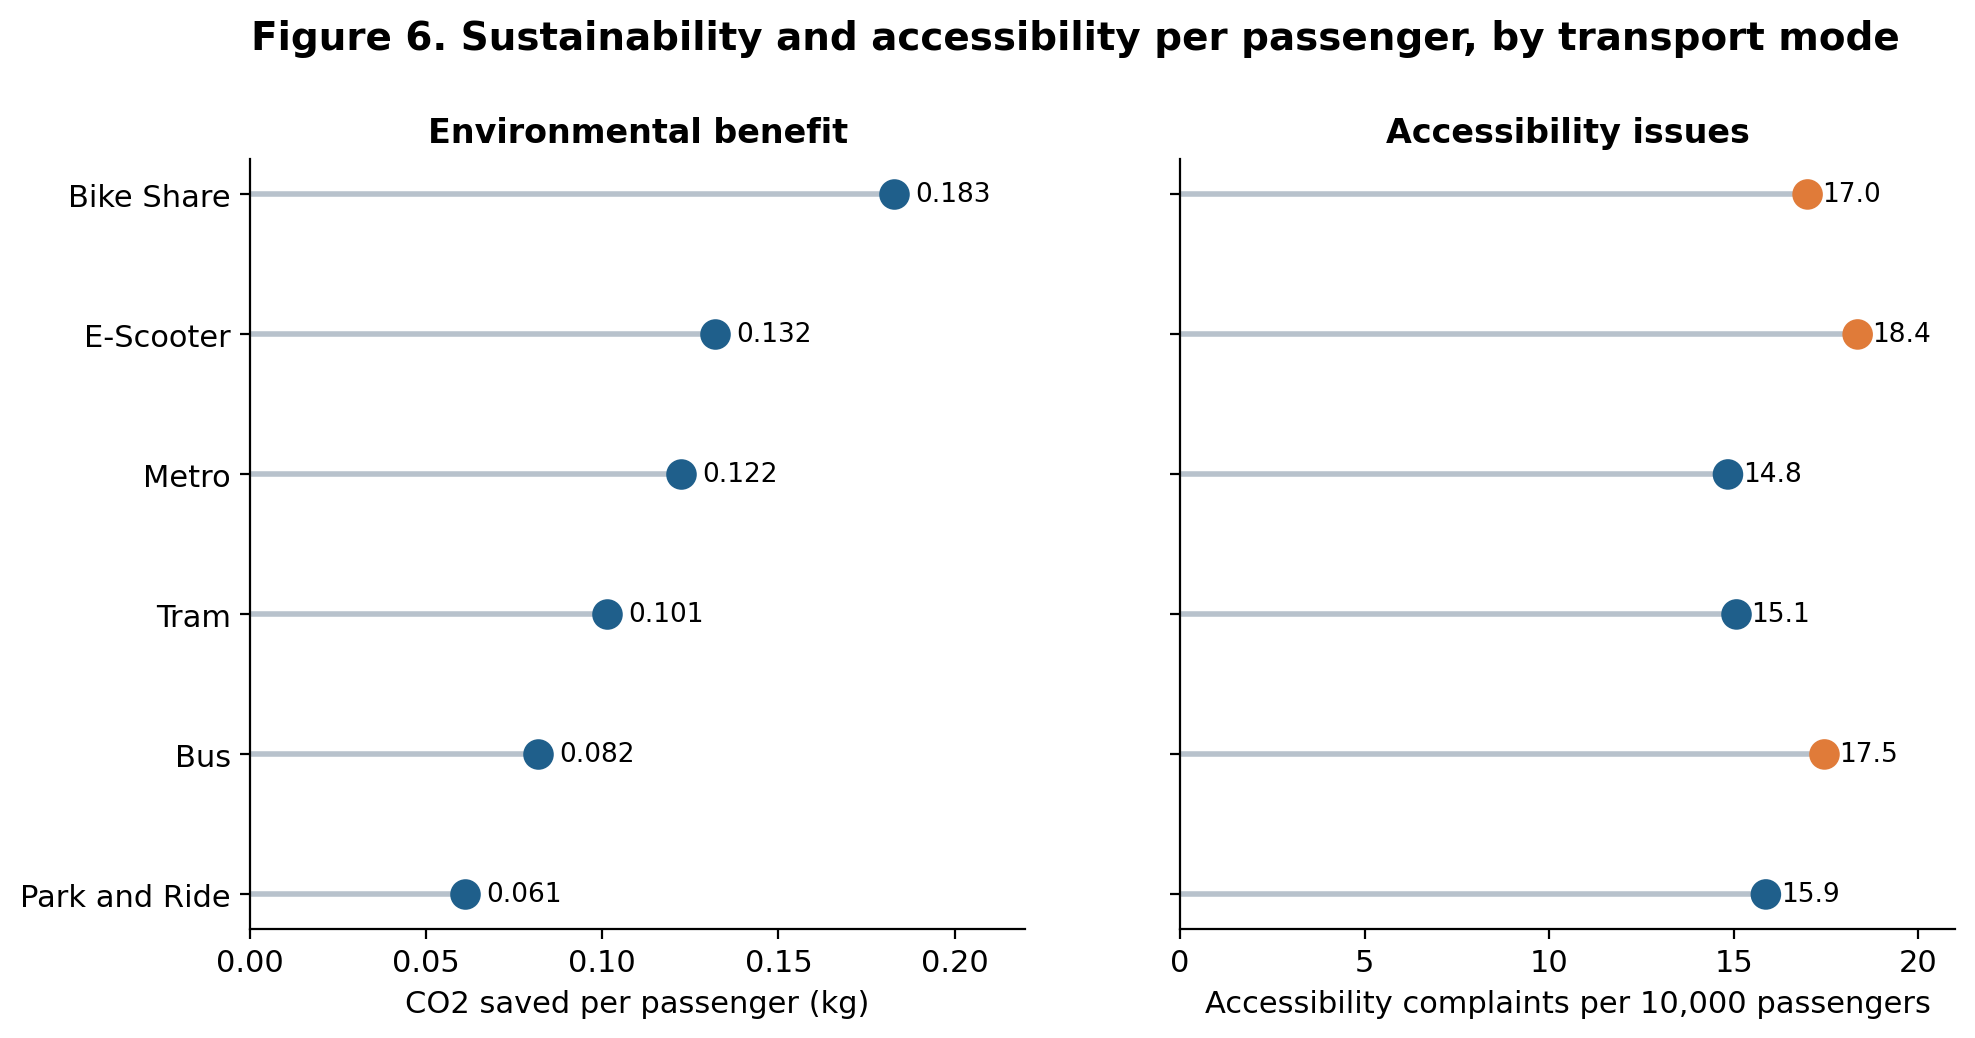

figures/fig7_event_day_effect.png


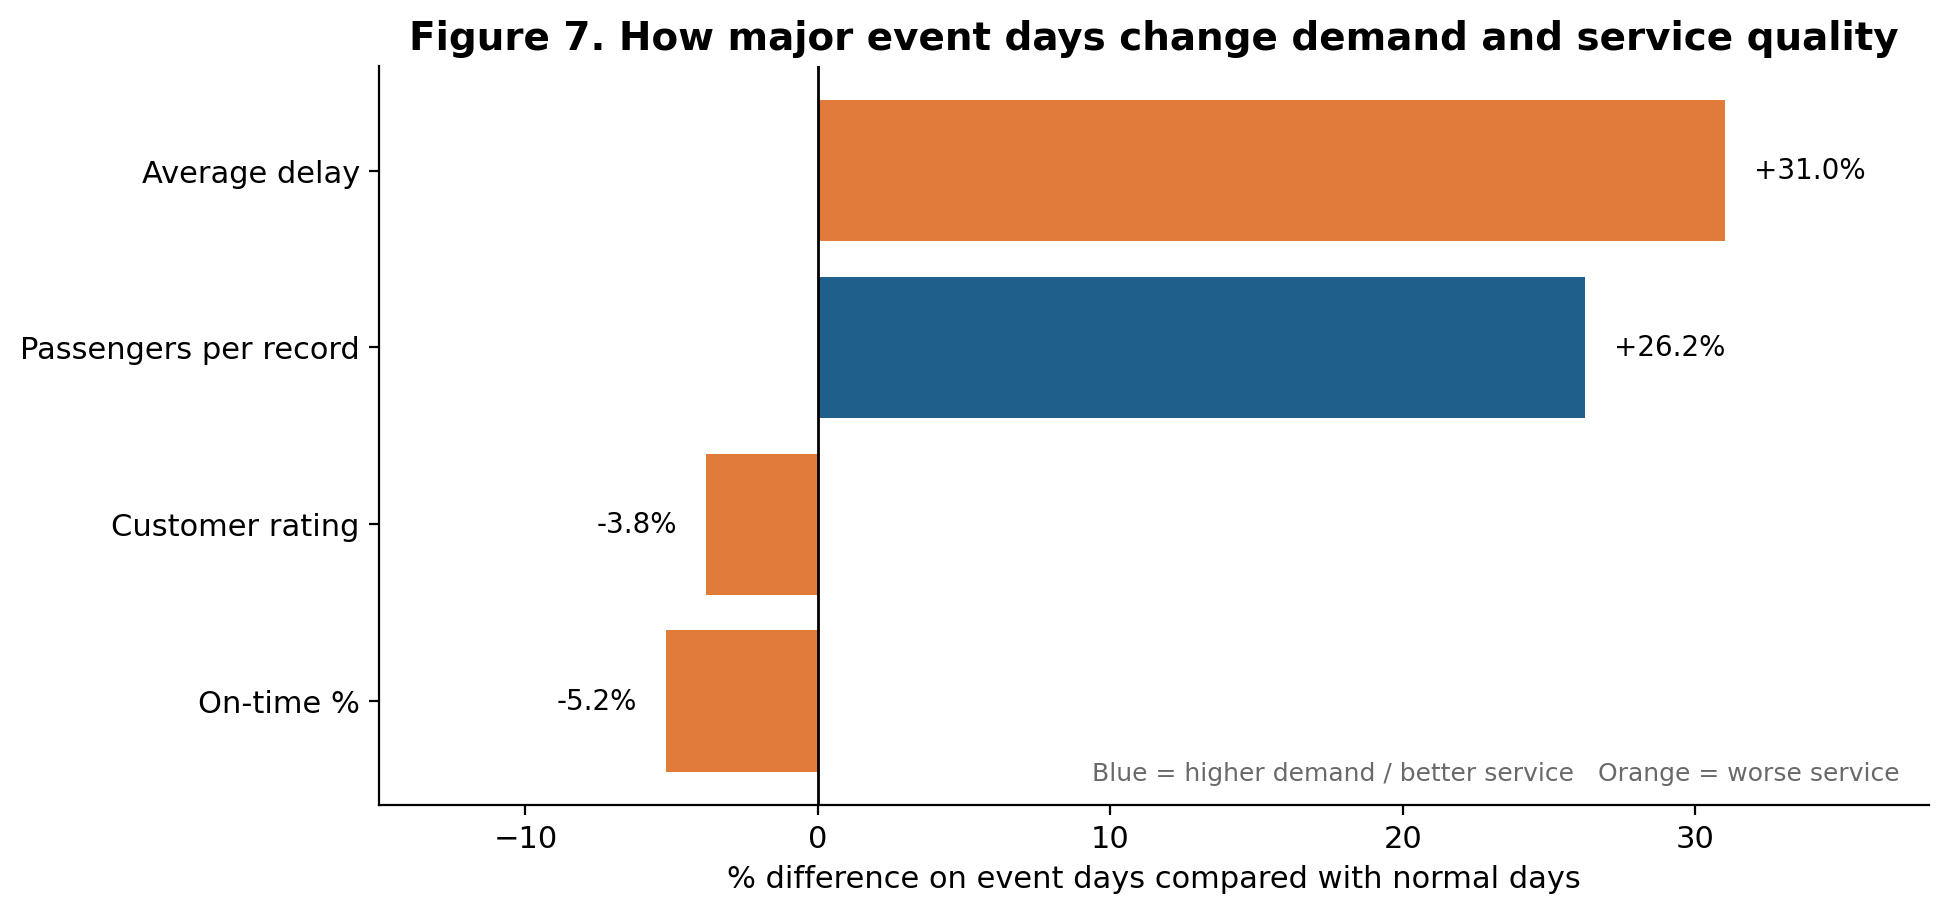

In [14]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("figures/*.png")):
    print(f)
    display(Image(filename=f, width=900))

## Step 5 – Interactive dashboard (Appendix B)
The dashboard opens inside the output below. Use the filters to explore the data.

In [18]:
"""
COM7021 Data Visualisation - EcoMove Mobility Investigation
Part 2: interactive dashboard for senior managers (Plotly Dash).

Run:  python ecomove_dashboard.py   then open http://127.0.0.1:8050
Needs: pandas, plotly, dash, openpyxl
"""

import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html, Input, Output

BLUE, ORANGE, GREY = "#1f5f8b", "#e07b39", "#b8c2cc"
MODE_COLOURS = {"Metro": "#1f5f8b", "Tram": "#4f9bc7", "Bus": "#e07b39",
                "Park and Ride": "#8c6bb1", "Bike Share": "#2e9e6a", "E-Scooter": "#c2a33d"}

# ---------- Load and prepare (same steps as the analysis script) ----------
df = pd.read_excel("EcoMoveMobility.xlsx", sheet_name="Dataset")
df["Date"] = pd.to_datetime("1899-12-30") + pd.to_timedelta(df["Date"], unit="D")
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

METRICS = {
    "Passengers": ("Passengers", "sum"),
    "Ticket revenue (€)": ("Ticket_Revenue_EUR", "sum"),
    "Operating cost (€)": ("Operating_Cost_EUR", "sum"),
    "CO2 saved (kg)": ("CO2_Saved_KG", "sum"),
    "Average delay (min)": ("Average_Delay_Minutes", "mean"),
    "On-time %": ("On_Time_Percentage", "mean"),
    "Customer rating": ("Customer_Rating", "mean"),
    "Accessibility complaints": ("Accessibility_Complaints", "sum"),
}


def options(col):
    return [{"label": v, "value": v} for v in sorted(df[col].unique())]


def dropdown(id_, col, label):
    return html.Div([
        html.Label(label, style={"fontWeight": "600", "fontSize": "13px"}),
        dcc.Dropdown(id=id_, options=options(col), multi=True, placeholder="All"),
    ], style={"flex": "1", "minWidth": "160px"})


def kpi_card(id_, title):
    return html.Div([
        html.Div(title, style={"fontSize": "12px", "color": "#555"}),
        html.Div(id=id_, style={"fontSize": "22px", "fontWeight": "700", "color": BLUE}),
    ], style={"background": "white", "padding": "10px 14px", "borderRadius": "8px",
              "boxShadow": "0 1px 3px rgba(0,0,0,.15)", "flex": "1", "minWidth": "130px"})


app = Dash(__name__)
app.title = "EcoMove Mobility Dashboard"

app.layout = html.Div(style={"fontFamily": "Arial, sans-serif", "background": "#f3f5f7",
                             "padding": "16px"}, children=[
    html.H2("EcoMove City Transport Authority - Sustainable Mobility Dashboard",
            style={"margin": "0 0 4px 0", "color": "#1b2a38"}),
    html.Div("Use the filters to explore demand, reliability, finance, accessibility and "
             "sustainability for 12 European cities (2024-2025).",
             style={"color": "#555", "marginBottom": "12px"}),

    # ---- Filters ----
    html.Div(style={"display": "flex", "gap": "12px", "flexWrap": "wrap",
                    "marginBottom": "12px"}, children=[
        html.Div([
            html.Label("Date range", style={"fontWeight": "600", "fontSize": "13px"}),
            dcc.DatePickerRange(id="dates", start_date=df.Date.min().date(),
                                end_date=df.Date.max().date(),
                                min_date_allowed=df.Date.min().date(),
                                max_date_allowed=df.Date.max().date(),
                                display_format="DD MMM YYYY"),
        ]),
        dropdown("country", "Country", "Country"),
        dropdown("city", "City", "City"),
        dropdown("mode", "Transport_Mode", "Transport mode"),
        dropdown("route", "Route_Type", "Route type"),
        dropdown("weather", "Weather", "Weather"),
        html.Div([
            html.Label("Event day", style={"fontWeight": "600", "fontSize": "13px"}),
            dcc.RadioItems(id="event", value="All", inline=True,
                           options=["All", "Yes", "No"]),
        ]),
    ]),

    # ---- KPI cards ----
    html.Div(style={"display": "flex", "gap": "10px", "flexWrap": "wrap",
                    "marginBottom": "12px"}, children=[
        kpi_card("k_pax", "Passengers"),
        kpi_card("k_rec", "Cost recovery"),
        kpi_card("k_delay", "Avg delay"),
        kpi_card("k_ontime", "On-time"),
        kpi_card("k_rating", "Customer rating"),
        kpi_card("k_co2", "CO2 saved"),
        kpi_card("k_comp", "Complaints / 10k pax"),
    ]),

    # ---- Metric selector used by the comparison charts ----
    html.Div([
        html.Label("Measure for comparison charts: ", style={"fontWeight": "600"}),
        dcc.Dropdown(id="metric", options=list(METRICS), value="Passengers",
                     clearable=False, style={"width": "260px", "display": "inline-block",
                                             "verticalAlign": "middle"}),
    ], style={"marginBottom": "8px"}),

    html.Div(style={"display": "grid", "gridTemplateColumns": "1fr 1fr", "gap": "10px"},
             children=[
        dcc.Graph(id="g_trend"), dcc.Graph(id="g_mode"),
        dcc.Graph(id="g_city"), dcc.Graph(id="g_scatter"),
    ]),
])


@app.callback(Output("city", "options"), Input("country", "value"))
def update_city_list(countries):
    """Only show the cities that belong to the chosen countries."""
    d = df if not countries else df[df.Country.isin(countries)]
    return [{"label": c, "value": c} for c in sorted(d.City.unique())]


def filter_data(start, end, country, city, mode, route, weather, event):
    d = df[(df.Date >= start) & (df.Date <= end)]
    for col, chosen in [("Country", country), ("City", city), ("Transport_Mode", mode),
                        ("Route_Type", route), ("Weather", weather)]:
        if chosen:
            d = d[d[col].isin(chosen)]
    if event != "All":
        d = d[d.Event_Day == event]
    return d


def style_fig(fig, title):
    fig.update_layout(title=title, template="plotly_white", height=340,
                      margin=dict(l=10, r=10, t=50, b=10), title_font_size=15)
    return fig


@app.callback(
    [Output(i, "children") for i in
     ["k_pax", "k_rec", "k_delay", "k_ontime", "k_rating", "k_co2", "k_comp"]] +
    [Output("g_trend", "figure"), Output("g_mode", "figure"),
     Output("g_city", "figure"), Output("g_scatter", "figure")],
    [Input("dates", "start_date"), Input("dates", "end_date"), Input("country", "value"),
     Input("city", "value"), Input("mode", "value"), Input("route", "value"),
     Input("weather", "value"), Input("event", "value"), Input("metric", "value")])
def update(start, end, country, city, mode, route, weather, event, metric):
    d = filter_data(start, end, country, city, mode, route, weather, event)
    if d.empty:
        empty = style_fig(px.scatter(), "No data for this selection")
        return ["-"] * 7 + [empty] * 4

    pax = d.Passengers.sum()
    kpis = [
        f"{pax/1e6:.2f}m",
        f"{d.Ticket_Revenue_EUR.sum() / d.Operating_Cost_EUR.sum() * 100:.0f}%",
        f"{d.Average_Delay_Minutes.mean():.1f} min",
        f"{d.On_Time_Percentage.mean():.1f}%",
        f"{d.Customer_Rating.mean():.2f} / 5",
        f"{d.CO2_Saved_KG.sum()/1000:,.0f} t",
        f"{d.Accessibility_Complaints.sum() / pax * 1e4:.1f}",
    ]

    col, how = METRICS[metric]

    # 1. Trend over time
    t = d.groupby("Month")[col].agg(how).reset_index()
    f1 = px.line(t, x="Month", y=col, markers=True, color_discrete_sequence=[BLUE],
                 labels={col: metric, "Month": ""})
    style_fig(f1, f"Monthly trend: {metric}")

    # 2. Comparison by transport mode
    m = d.groupby("Transport_Mode")[col].agg(how).sort_values().reset_index()
    f2 = px.bar(m, x=col, y="Transport_Mode", orientation="h", color="Transport_Mode",
                color_discrete_map=MODE_COLOURS, labels={col: metric, "Transport_Mode": ""})
    f2.update_layout(showlegend=False)
    style_fig(f2, f"{metric} by transport mode")

    # 3. Comparison by city (top value highlighted)
    c = d.groupby("City")[col].agg(how).sort_values().reset_index()
    c["Highlight"] = ["Top" if i == len(c) - 1 else "Other" for i in range(len(c))]
    f3 = px.bar(c, x=col, y="City", orientation="h", color="Highlight",
                color_discrete_map={"Top": ORANGE, "Other": BLUE},
                labels={col: metric, "City": ""})
    f3.update_layout(showlegend=False)
    style_fig(f3, f"{metric} by city")

    # 4. Reliability vs satisfaction (one bubble per city and mode)
    s = d.groupby(["City", "Transport_Mode"]).agg(
        Delay=("Average_Delay_Minutes", "mean"), Rating=("Customer_Rating", "mean"),
        Passengers=("Passengers", "sum")).reset_index()
    f4 = px.scatter(s, x="Delay", y="Rating", size="Passengers", color="Transport_Mode",
                    color_discrete_map=MODE_COLOURS, hover_name="City", size_max=30,
                    labels={"Delay": "Average delay (min)", "Rating": "Customer rating",
                            "Transport_Mode": "Mode"})
    style_fig(f4, "Delay vs customer rating (bubble = passengers)")

    return kpis + [f1, f2, f3, f4]


if __name__ == "__main__":
    app.run(debug=False, port=8050)

<IPython.core.display.Javascript object>